# 21 · A6: does the shared space find land types it never saw?

Matt: *"yes, score the never-seen words against OpenStreetMap"*. Everything here is fixed in `PLAN.md`
(amendment A6) and `configs/unseen_words.yaml` before any model output.

- **Model:** the demo's shared space (CLIP projector from notebook 11): each demo cell's projected vector and the
  CLIP vector of a plain phrase; score = cosine similarity.
- **Never-seen words:** 24 land uses or features absent from training (checked against all 510,930 training
  captions), each with an OpenStreetMap answer key from a new Overpass request (areas, lines buffered 30 m, points
  buffered 60 m).
- **Reference:** the 23 OpenStreetMap tags used in training, with their first training word.
- **Score:** average precision (AP) against the answer key, relative to chance (the key's share of cells);
  (word, area) pairs with ≥ 20 answer-key cells; control = block-shuffled answer keys; bootstrap by word.
- **Pass marks:** K6 control median AP/chance ≤ 1.5; U1 never-seen median AP/chance ≥ 2 with 95% lower bound > 1
  (needs ≥ 5 eligible words).

In [1]:
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from askmap.aether_us import TextEncoder
from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.demo.serve import load_tiles
from askmap.geo import tile_bbox_4326
from askmap.manifest import Manifest
from askmap.osm import fetch_overpass, tag_layers
from askmap.tiles import area_tiles
from askmap.unseen import (
    ap_and_chance,
    block_shuffle,
    bootstrap_median_by_word,
    bootstrap_median_difference,
    overpass_query_selectors,
    rule_mask,
    terms_in_captions,
)

T_START = time.time()
cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
UC = load_config(PROJECT_ROOT / "configs" / "unseen_words.yaml")
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
DEMO = ROOT / "demo"
META = json.loads((DEMO / "meta.json").read_text())
STRIDE = META["stride"]
DT = load_tiles(DEMO, META)  # area -> demo TileData (valid cells, projected vectors z)
GEOM = {}
for area in META["areas"]:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        if role == "test":
            GEOM[name] = (area, tile)
for tiles in DT.values():
    for t in tiles:
        rows = -(-GEOM[t.name][1].size_px // STRIDE)
        if t.valid.shape != (rows, rows) or t.z.shape[0] != int(t.valid.sum()):
            raise ValueError(f"demo grid of {t.name} does not match the tile geometry")
print({a: [t.name for t in ts] for a, ts in DT.items()}, "grid", DT["north_dakota"][0].valid.shape)

{'north_dakota': ['Kidder', 'Foster', 'Eddy'], 'north_carolina': ['NC4', 'NC5', 'NC6'], 'minnesota': ['MN1', 'MN2', 'MN3'], 'georgia': ['GA1', 'GA2', 'GA3']} grid (223, 223)


## Check V0: the never-seen words really are absent from the training captions

In [2]:
UNSEEN = UC["unseen"]
captions = np.load(ROOT / "aether_us" / "text_clip.npz")["strings"].tolist()
print(f"{len(captions):,} training captions")
found = {w: sorted(terms_in_captions(captions, v["check"])) for w, v in UNSEEN.items()}
DROPPED = {w: f for w, f in found.items() if f}
WORDS = [w for w in UNSEEN if w not in DROPPED]
del captions
print("dropped (a check term occurs in a training caption):", DROPPED or "none")
print(f"{len(WORDS)} never-seen words kept")

289,375 training captions


dropped (a check term occurs in a training caption): none
24 never-seen words kept


## OpenStreetMap: one new Overpass request per demo tile (saved, with a manifest)

In [3]:
OV = UC["overpass"]
OSM_NEW = ROOT / "osm_unseen"
OSM_NEW.mkdir(exist_ok=True)
man = Manifest(OSM_NEW)
NEW_EL, OLD_EL = {}, {}
for name, (area, tile) in GEOM.items():
    raw = OSM_NEW / f"{area}_{name}.json"
    query = overpass_query_selectors(tile_bbox_4326(tile), OV["selectors"], OV["timeout_s"])
    fresh = not raw.exists()
    data = fetch_overpass(query, OV["url"], raw, OV["retries"], OV["wait_s"], OV["user_agent"])
    if fresh:
        man.record(raw, source=OV["url"], query=query, tile=name, area=area)
        time.sleep(OV["pause_s"])
    NEW_EL[name] = data["elements"]
    old = ROOT / "osm" / f"{area}_{name}.json"
    if not old.exists():
        raise FileNotFoundError(f"notebook 10's saved reply is missing: {old}")
    OLD_EL[name] = json.loads(old.read_text())["elements"]
print({n: len(e) for n, e in NEW_EL.items()})

{'Kidder': 381, 'Foster': 255, 'Eddy': 510, 'NC4': 3476, 'NC5': 2845, 'NC6': 1286, 'MN1': 565, 'MN2': 1723, 'MN3': 1248, 'GA1': 2334, 'GA2': 1205, 'GA3': 464}


## Answer keys on the demo grid, and eligibility (counts only)

In [4]:
USED = pd.read_csv(PROJECT_ROOT / UC["reference_from"]).entry.tolist()
VOCAB = AU["osm"]["vocab"]
KEYS = {}  # (group, word) -> {tile: mask on the demo grid}
for w in WORDS:
    KEYS[("never-seen", w)] = {
        n: rule_mask(NEW_EL[n], GEOM[n][1], UNSEEN[w], UC["line_buffer_m"], UC["point_buffer_m"], STRIDE)
        for n in GEOM
    }
for k in USED:
    KEYS[("trained", k)] = {
        n: tag_layers(OLD_EL[n], GEOM[n][1], {k: VOCAB[k]})[k][::STRIDE, ::STRIDE] for n in GEOM
    }
rows = []
for (group, w), masks in KEYS.items():
    for area, tiles in DT.items():
        cnt = int(sum((masks[t.name] & t.valid).sum() for t in tiles))
        rows.append({"group": group, "word": w, "area": area, "key_cells": cnt})
COUNTS = pd.DataFrame(rows)
ELIG = COUNTS[COUNTS.key_cells >= UC["min_cells"]]
print("eligible (word, area) pairs:", ELIG.groupby("group").size().to_dict())
COUNTS.pivot_table(index=["group", "word"], columns="area", values="key_cells", sort=False)

eligible (word, area) pairs: {'never-seen': 46, 'trained': 69}


area                         north_dakota  north_carolina  minnesota  georgia
group      word                                                              
never-seen airport                   13.0           135.0      514.0   2105.0
           railway                  245.0           524.0      285.0    814.0
           highway                  356.0          2099.0     1166.0   2224.0
           dirt_track              5084.0          1063.0      414.0   1614.0
           wind_turbines              0.0             0.0        0.0      0.0
           power_lines              658.0          1575.0     2479.0   2128.0
           parking                    2.0            38.0      210.0    277.0
           school                     0.0           161.0      201.0    313.0
           church                     0.0             2.0       55.0     28.0
           hospital                   0.0            29.0       15.0     35.0
           orchard                    0.0             0.0        0.0    235.0
           vineyard                   0.0             0.0        0.0      0.0
           landfill                   0.0            97.0        0.0      1.0
           greenhouses                0.0             1.0        0.0      0.0
           plant_nursery              0.0            37.0        6.0      0.0
           grain_elevator            10.0             3.0        9.0      0.0
           stadium                    0.0             8.0        1.0     10.0
           creek                    625.0         10822.0     4370.0   3972.0
           ditch                      0.0           915.0     1707.0     66.0
           tree_row                   3.0            86.0      138.0     96.0
           radio_mast                 5.0            70.0       55.0    101.0
           oil_well                   0.0             0.0        0.0      0.0
           dam                        2.0             0.0        0.0     60.0
           levee                      0.0             0.0        0.0      0.0
trained    osm_farmland             588.0          1630.0     1702.0   2828.0
           osm_meadow                 0.0           132.0       24.0     83.0
           osm_grass                 38.0            20.0      528.0   1067.0
           osm_forest                 9.0          2679.0     2738.0   6976.0
           osm_scrub                  0.0             6.0        4.0     89.0
           osm_residential          112.0           312.0     6525.0   1491.0
           osm_industrial             8.0            51.0     1573.0    956.0
           osm_commercial            11.0            77.0      590.0    350.0
           osm_quarry                42.0            73.0      223.0    228.0
           osm_cemetery               0.0            60.0       68.0     86.0
           osm_farmyard              19.0             7.0      145.0     17.0
           osm_construction           0.0            42.0       14.0     46.0
           osm_recreation             0.0           212.0      811.0    474.0
           osm_golf                   0.0           171.0      418.0    384.0
           osm_reserve                0.0           837.0    10773.0      0.0
           osm_wetland             1808.0          3427.0      126.0   2450.0
           osm_swamp                  0.0          1107.0        2.0   2025.0
           osm_water               6496.0          1628.0     2225.0   1655.0
           osm_pond                   0.0           353.0       23.0    529.0
           osm_lake                2864.0            93.0      400.0    374.0
           osm_river                 36.0           580.0     1197.0     96.0
           osm_wastewater             0.0             9.0       30.0     42.0
           osm_solar                  0.0           961.0      777.0   1324.0

## Scores: the phrase's CLIP vector against each cell's shared-space vector

In [5]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
enc = TextEncoder(META["encoder"], META["encoder_kind"], device, os.environ["HF_HOME"])
TEXT = {("never-seen", w): UNSEEN[w]["text"] for w in WORDS}
TEXT |= {("trained", k): VOCAB[k]["words"][0] for k in USED}
keys = list(TEXT)
Q = enc([TEXT[k] for k in keys])
Q = Q / np.linalg.norm(Q, axis=1, keepdims=True)
QV = dict(zip(keys, Q, strict=True))
rng = np.random.default_rng(UC["control"]["seed"])
out = []
for r in ELIG.itertuples():
    k, tiles = (r.group, r.word), DT[r.area]
    truth = np.concatenate([KEYS[k][t.name][t.valid] for t in tiles])
    score = np.concatenate([t.z.astype(np.float32) @ QV[k] for t in tiles])
    ap, chance = ap_and_chance(truth, score)
    shuf = np.concatenate(
        [block_shuffle(KEYS[k][t.name], UC["control"]["block_cells"], rng)[t.valid] for t in tiles]
    )
    ap_s, chance_s = ap_and_chance(shuf, score)
    out.append(
        {
            "group": r.group,
            "word": r.word,
            "text": TEXT[k],
            "area": r.area,
            "key_cells": r.key_cells,
            "AP": ap,
            "chance": chance,
            "ratio": ap / chance,
            "AP_minus_chance": ap - chance,
            "control_ratio": ap_s / chance_s,
        }
    )
S = pd.DataFrame(out)
S.to_csv(RES / "21_unseen_words.csv", index=False)
S.sort_values(["group", "ratio"], ascending=[True, False]).round(3)

/Volumes/disco2/github/ask-the-map-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 19:58:11.653000 61086 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 17884.74it/s]

,group,word,text,area,key_cells,AP,chance,ratio,AP_minus_chance,control_ratio
21,never-seen,parking,a parking lot,georgia,277,0.091,0.002,48.815,0.089,2.035
20,never-seen,parking,a parking lot,minnesota,210,0.060,0.001,42.773,0.059,1.489
28,never-seen,hospital,a hospital,georgia,35,0.009,0.000,38.692,0.009,0.712
19,never-seen,parking,a parking lot,north_carolina,38,0.009,0.000,35.769,0.009,7.984
7,never-seen,highway,a highway,north_dakota,356,0.054,0.002,22.516,0.051,1.992
...,...,...,...,...,...,...,...,...,...,...
57,trained,osm_forest,woods,north_carolina,2679,0.025,0.018,1.407,0.007,1.123
79,trained,osm_construction,a construction site,north_carolina,42,0.000,0.000,0.984,-0.000,0.890
78,trained,osm_farmyard,a farmyard,minnesota,145,0.001,0.001,0.921,-0.000,0.929
60,trained,osm_scrub,scrub,georgia,89,0.001,0.001,0.918,-0.000,0.934


## Verdicts

In [6]:
B = UC["bootstrap"]
nv, tr = S[S.group == "never-seen"], S[S.group == "trained"]
n_words = nv.word.nunique()
k6 = float(S.control_ratio.median())
v = {
    "never_seen_words_kept": WORDS,
    "dropped_by_V0": DROPPED,
    "eligible_pairs": len(nv),
    "eligible_words": int(n_words),
    "K6_control_median_ratio": round(k6, 3),
    "K6_pass": k6 <= 1.5,
}
if n_words >= 2:
    m, lo, hi = bootstrap_median_by_word(nv.word.values, nv.ratio.values, B["n"], B["seed"])
    v["U1_median_ratio"], v["U1_lo"], v["U1_hi"] = round(m, 3), round(lo, 3), round(hi, 3)
if n_words < 5:
    v["U1"] = "INCONCLUSIVE (fewer than 5 eligible never-seen words)"
elif not v["K6_pass"]:
    v["U1"] = "NOT JUDGED (control K6 failed)"
else:
    v["U1"] = "PASS" if (v["U1_median_ratio"] >= 2 and v["U1_lo"] > 1) else "FAIL"
m, lo, hi = bootstrap_median_by_word(tr.word.values, tr.ratio.values, B["n"], B["seed"])
v["trained_median_ratio"], v["trained_lo"], v["trained_hi"] = round(m, 3), round(lo, 3), round(hi, 3)
if n_words >= 2:
    d, lo, hi = bootstrap_median_difference(
        nv.word.values, nv.ratio.values, tr.word.values, tr.ratio.values, B["n"], B["seed"]
    )
    v["difference_never_seen_minus_trained"] = [round(d, 3), round(lo, 3), round(hi, 3)]
v["median_AP_minus_chance"] = {
    "never-seen": round(float(nv.AP_minus_chance.median()), 4),
    "trained": round(float(tr.AP_minus_chance.median()), 4),
}
(RES / "21_verdicts.json").write_text(json.dumps(v, indent=1))
v

{'never_seen_words_kept': ['airport',
  'railway',
  'highway',
  'dirt_track',
  'wind_turbines',
  'power_lines',
  'parking',
  'school',
  'church',
  'hospital',
  'orchard',
  'vineyard',
  'landfill',
  'greenhouses',
  'plant_nursery',
  'grain_elevator',
  'stadium',
  'creek',
  'ditch',
  'tree_row',
  'radio_mast',
  'oil_well',
  'dam',
  'levee'],
 'dropped_by_V0': {},
 'eligible_pairs': 46,
 'eligible_words': 17,
 'K6_control_median_ratio': 1.421,
 'K6_pass': True,
 'U1_median_ratio': 2.335,
 'U1_lo': 1.784,
 'U1_hi': 7.016,
 'U1': 'PASS',
 'trained_median_ratio': 15.782,
 'trained_lo': 4.493,
 'trained_hi': 36.473,
 'difference_never_seen_minus_trained': [-13.447, -33.78, -1.381],
 'median_AP_minus_chance': {'never-seen': 0.0051, 'trained': 0.0346}}

## Figure: AP relative to chance, per word (dots = areas); never-seen words against trained OpenStreetMap tags

Run time 0.5 min


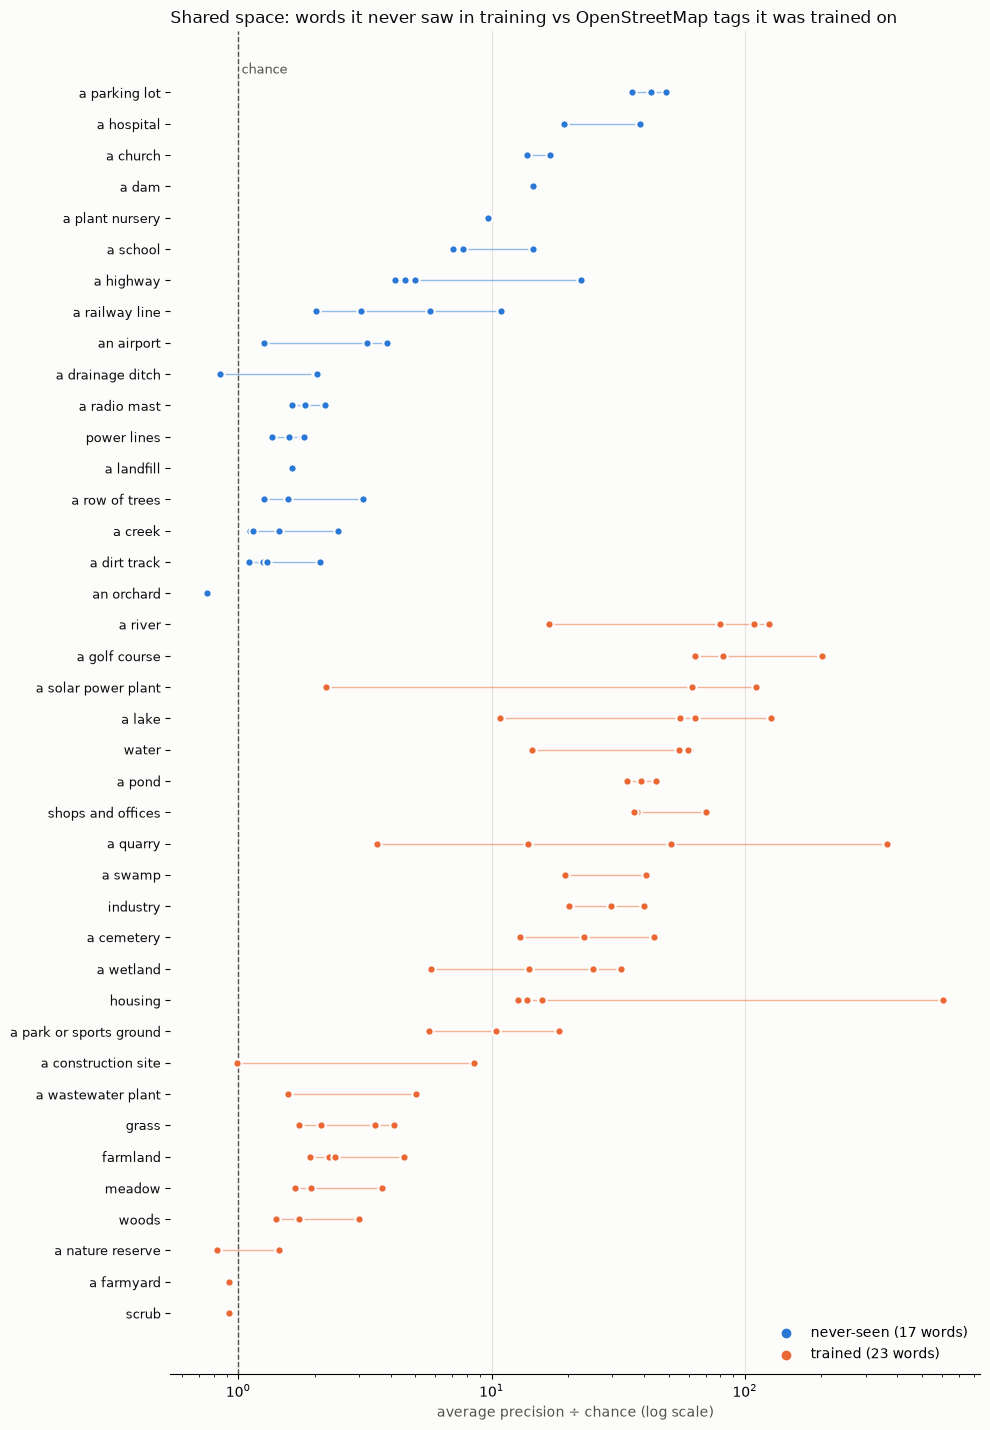

In [7]:
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COL = {"never-seen": "#2a78d6", "trained": "#eb6834"}
order = (
    S.groupby(["group", "text"])
    .ratio.median()
    .reset_index()
    .sort_values(["group", "ratio"], ascending=[False, True])
)
fig, ax = plt.subplots(figsize=(10, 0.32 * len(order) + 1.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for y, r in enumerate(order.itertuples()):
    pts = S[(S.group == r.group) & (S.text == r.text)]
    ax.scatter(
        pts.ratio, [y] * len(pts), s=36, color=COL[r.group], edgecolor=SURFACE, linewidth=1.5, zorder=3
    )
    ax.plot([pts.ratio.min(), pts.ratio.max()], [y, y], color=COL[r.group], lw=1, alpha=0.5, zorder=2)
ax.axvline(1, color=INK2, ls="--", lw=1)
ax.text(1.03, len(order) - 0.4, "chance", color=INK2, fontsize=9)
ax.set_xscale("log")
ax.set_yticks(range(len(order)), [f"{t}" for t in order.text], fontsize=9, color=INK)
ax.set_xlabel("average precision ÷ chance (log scale)", color=INK2)
for g, c in COL.items():
    ax.scatter([], [], color=c, label=f"{g} ({S[S.group == g].word.nunique()} words)")
ax.legend(loc="lower right", frameon=False)
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.set_title(
    "Shared space: words it never saw in training vs OpenStreetMap tags it was trained on",
    loc="left",
    fontsize=12,
    color=INK,
)
fig.tight_layout()
fig.savefig(FIG / "21_unseen_words.png", dpi=200, bbox_inches="tight")
print(f"Run time {(time.time() - T_START) / 60:.1f} min")